# P1: Reading mAP

**Object detection practices.** Interpreting detection metrics: the PR curve, its traps, and where the missing mAP goes.

We run this notebook together in class. Every cell is an experiment: we look at the output and interpret it. You don't need to write any code.

| § | Topic |
|---|---|
| 1 | The toy scene |
| 2 | IoU |
| 3 | Matching: who gets the credit |
| 4 | The PR curve and AP |
| 5 | From AP to mAP: classes |
| 6 | mAP@.5 vs mAP@[.5:.95] |
| 7 | Checking against pycocotools |
| 8 | Breaking the metric |
| 9 | Error analysis: where is the missing mAP? (TIDE) |

## 0. Setup
Runs on Colab, Kaggle, the cluster or a laptop. No GPU needed.

In [1]:
try:
    import pycocotools  # preinstalled on Colab and Kaggle
except ImportError:
    %pip install -q pycocotools

%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import mapviz as mv


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\Acer\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


---
## 1. The toy scene

One synthetic image: 6 cars (white = ground truth) and 10 detections (blue, labelled `#rank score`).

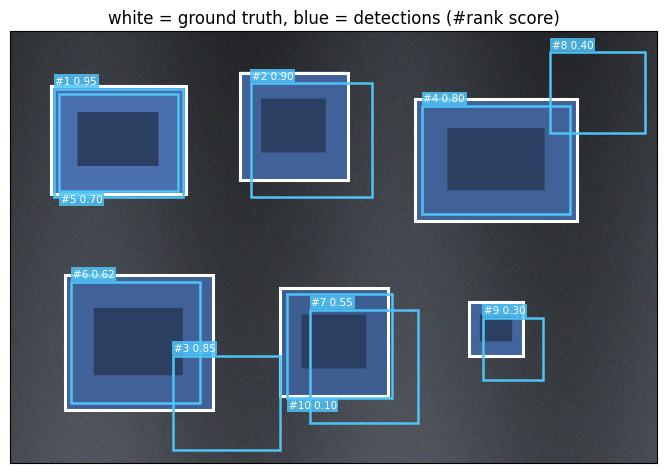

In [2]:
gts, preds = mv.scene_a()
mv.show_scene(gts, preds)

---
## 2. IoU

$$\mathrm{IoU}(A,B)=\frac{|A\cap B|}{|A\cup B|}$$

In [3]:
a = (0, 0, 100, 60)
print("shifted half a width   :", round(mv.iou(a, (50, 0, 150, 60)), 3))
print("shrunk to 70% (w and h) :", round(mv.iou(a, (15, 9, 85, 51)), 3))
print("small car (20 px), 4 px shift:", round(mv.iou((0, 0, 20, 20), (4, 4, 24, 24)), 3))
print("big car (200 px), 4 px shift :", round(mv.iou((0, 0, 200, 200), (4, 4, 204, 204)), 3))

shifted half a width   : 0.333
shrunk to 70% (w and h) : 0.49
small car (20 px), 4 px shift: 0.471
big car (200 px), 4 px shift : 0.924


---
## 3. Matching: who gets the credit

Greedy rule (VOC and COCO):
1. Sort the detections by score, highest first.
2. Each detection takes the **still unmatched** GT with the highest IoU, if that IoU ≥ threshold → **TP**.
3. Otherwise → **FP**.
4. GT boxes that are never matched → **FN** (missed).

### 3.1 IoU threshold 0.5

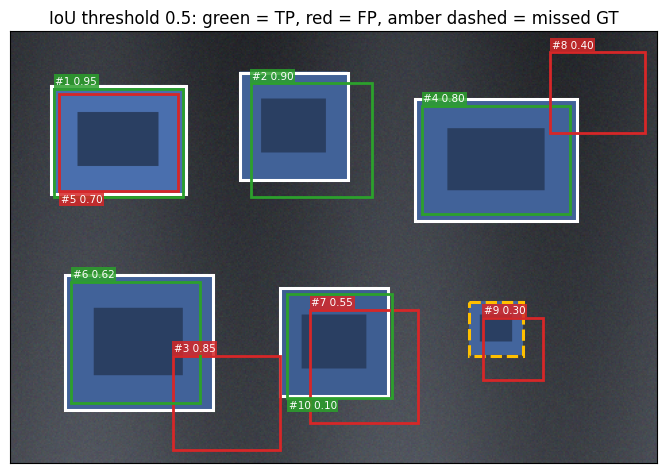

In [4]:
mv.show_scene(gts, preds, iou_thr=0.5)

### 3.2 IoU threshold 0.35

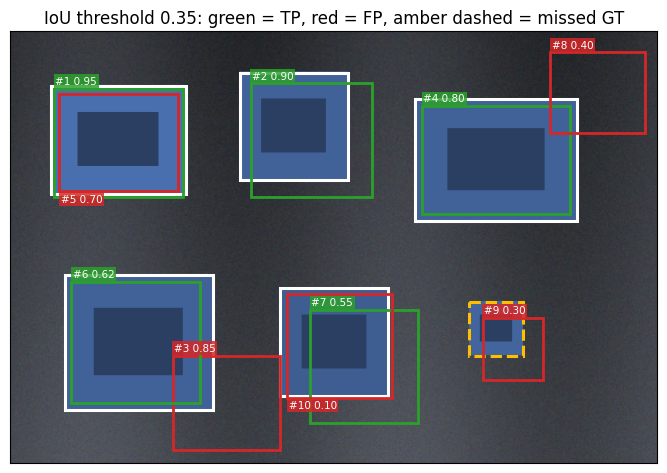

In [5]:
mv.show_scene(gts, preds, iou_thr=0.35)

---
## 4. The PR curve and AP

Walk down the ranked list. After each detection:

$$\text{precision}=\frac{TP_{\text{so far}}}{\text{detections so far}}\qquad \text{recall}=\frac{TP_{\text{so far}}}{\#\text{GT}}$$

**AP** is the area under that curve.

Explorer controls:
- **top-k kept**: how many of the ranked detections you keep, which is the same as choosing a confidence threshold. ▶ plays it one detection at a time.
- **IoU thr**: what counts as a TP.
- ◆ marks the **operating point** at the current threshold.

In [6]:
mv.pr_explorer(gts, preds)

Output()

---
## 5. From AP to mAP: classes

**mAP = the mean over classes of the per-class AP.** Toy data: 6 images, a frequent class (`car`) and a rare one (`bike`).

26 cars, 4 bikes, 43 detections


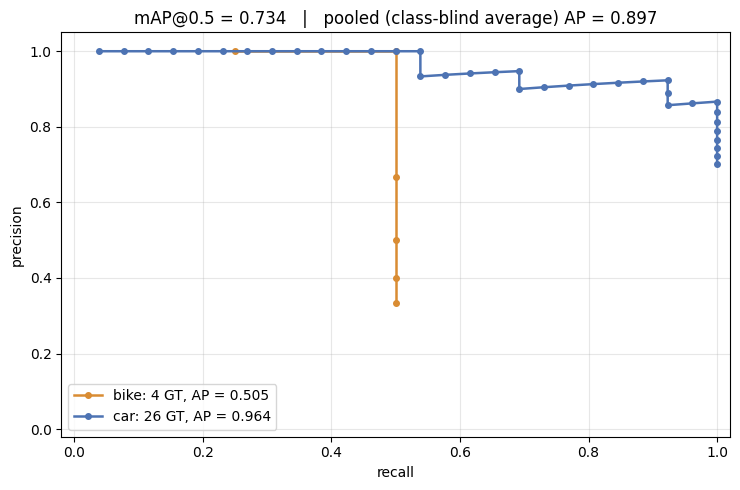

In [7]:
gts5 = mv.make_dataset(seed=0, n_imgs=6, n_bikes=4)
preds5 = mv.simulate_detector(gts5, seed=0, recall={"car": 0.95, "bike": 0.5}, jitter=0.05, confuse_rate=0.05)
print(f"{sum(g['cls']=='car' for g in gts5)} cars, {sum(g['cls']=='bike' for g in gts5)} bikes, {len(preds5)} detections")
mv.plot_per_class(gts5, preds5)

---
## 6. mAP@.5 vs mAP@[.5:.95]

COCO's headline number averages AP over the IoU thresholds 0.50, 0.55, …, 0.95. Two simulated detectors on the same data:
- **A**: finds a bit fewer objects, tight boxes
- **B**: finds almost everything, sloppy boxes

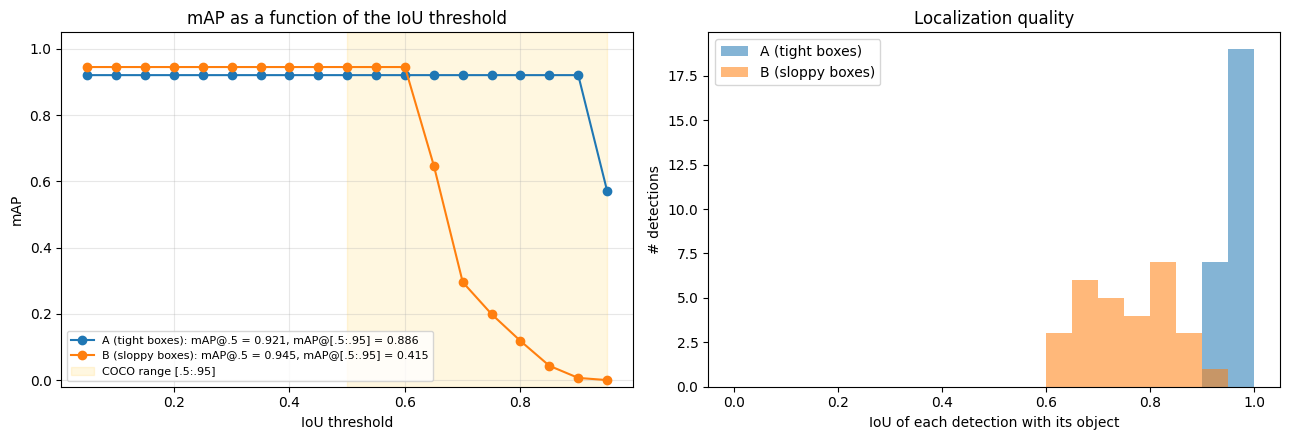

In [8]:
model_A = mv.simulate_detector(gts5, seed=1,   recall={"car": 0.85, "bike": 0.85}, jitter=0.015, bg_per_img=1)
model_B = mv.simulate_detector(gts5, seed=101, recall={"car": 0.95, "bike": 0.95}, jitter=0.08,  bg_per_img=1)
mv.plot_ap_vs_iou(gts5, {"A (tight boxes)": model_A, "B (sloppy boxes)": model_B})

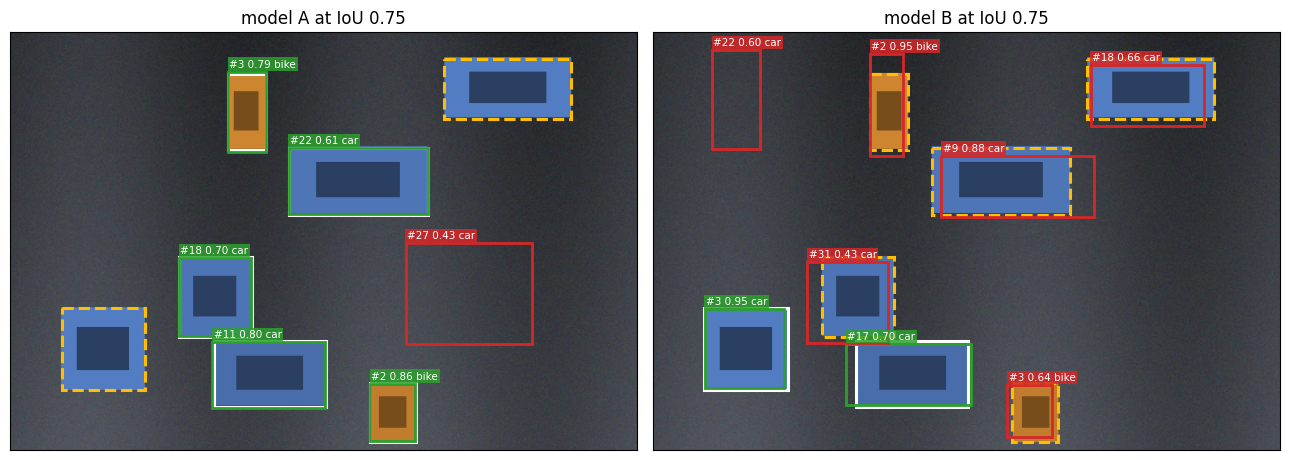

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (name, P) in zip(axes, [("A", model_A), ("B", model_B)]):
    mv.draw_scene(ax, gts5, P, img="img1", matches=mv.match(gts5, P, 0.75)); ax.set_title(f"model {name} at IoU 0.75")
plt.tight_layout(); plt.show()

---
## 7. Checking against pycocotools

### 7.1 Our implementation vs. the official COCO evaluator

In [10]:
ours = dict(mAP=mv.map_coco(gts5, preds5), mAP50=mv.map50(gts5, preds5),
            mAP75=mv.evaluate(gts5, preds5, 0.75)["mAP"])
coco = mv.pycoco_eval(gts5, preds5)
for k in ours:
    print(f"{k:6s}  ours = {ours[k]:.4f}   pycocotools = {coco[k]:.4f}")

mAP     ours = 0.5241   pycocotools = 0.5241
mAP50   ours = 0.7343   pycocotools = 0.7343
mAP75   ours = 0.7164   pycocotools = 0.7164


### 7.2 A crowded scene: 120 birds in one image

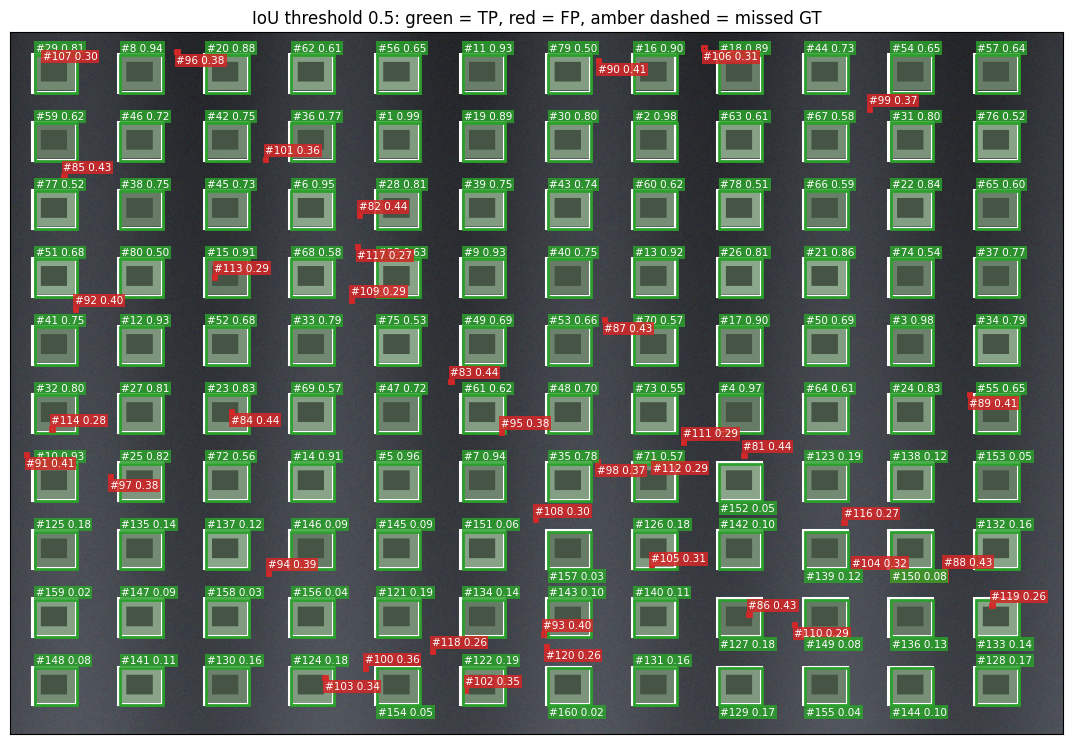

120 GT, 160 detections
ours, AP@.5        : 0.9158
pycocotools, AP@.5 : 0.6634


In [11]:
gts7, preds7, size7 = mv.scene_many_dets()
mv.show_scene(gts7, preds7, iou_thr=0.5, size=size7, figsize=(11, 7.5))
print(f"{len(gts7)} GT, {len(preds7)} detections")
print("ours, AP@.5        :", round(mv.map50(gts7, preds7), 4))
print("pycocotools, AP@.5 :", round(mv.pycoco_eval(gts7, preds7, img_size=size7)["mAP50"], 4))

In [12]:
print("ours, keeping only the top 100 detections per image:", round(mv.map50(gts7, preds7, max_dets=100), 4))
print("pycocotools with maxDets = 300                      :",
      round(mv.pycoco_eval(gts7, preds7, img_size=size7, max_dets=(1, 10, 300))["mAP50"], 4))

ours, keeping only the top 100 detections per image: 0.6634
pycocotools with maxDets = 300                      : 0.9158


---
## 8. Breaking the metric

Four small edits to the scene from §1, each compared with the original.

### 8.1 Change only the scores (same boxes): every TP scored above every FP

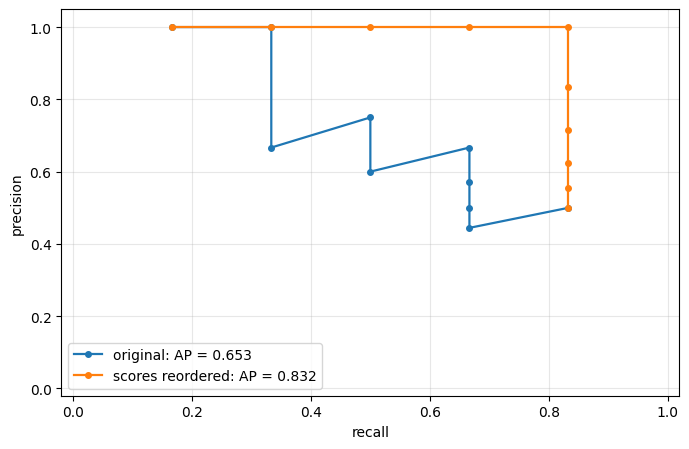

In [13]:
m = mv.match(gts, preds, 0.5)
reordered = [dict(p, score=0.9 + 0.01 * p["score"] if mm["status"] == "TP" else 0.1 * p["score"])
             for p, mm in zip(preds, m)]
mv.plot_pr_compare(gts, {"original": preds, "scores reordered": reordered})

### 8.2 Add 20 random boxes with score 0.01

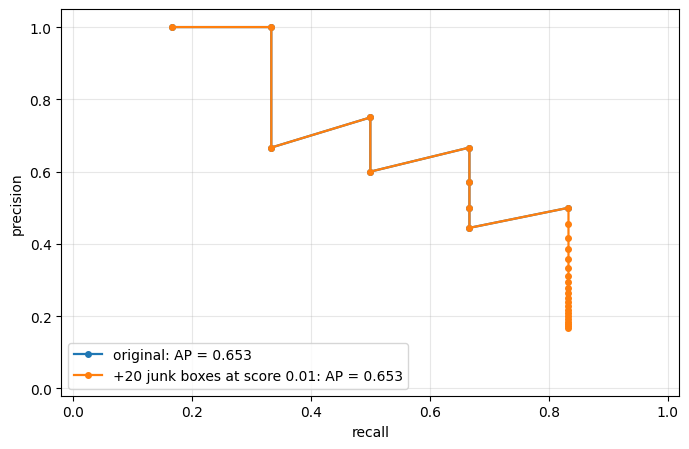

In [14]:
junk = mv.add_junk(preds, n=20, score=0.01, seed=0)
mv.plot_pr_compare(gts, {"original": preds, "+20 junk boxes at score 0.01": junk})

### 8.3 Add one background box: once with score 0.99, once with score 0.01

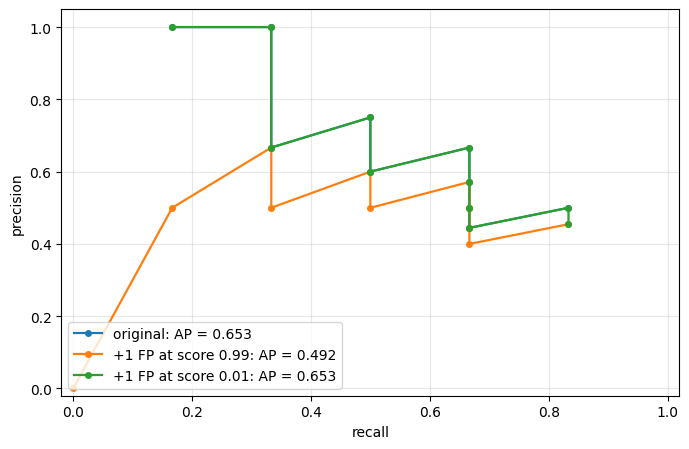

In [15]:
fp = dict(img="scene_a", cls="car", box=(400, 250, 460, 300))
mv.plot_pr_compare(gts, {"original": preds,
                         "+1 FP at score 0.99": preds + [dict(fp, score=0.99)],
                         "+1 FP at score 0.01": preds + [dict(fp, score=0.01)]})

### 8.4 Two detectors: perfect boxes vs. boxes with IoU 0.62, same scores

In [16]:
perfect = [dict(g, score=0.9) for g in gts]
loose = [dict(g, box=mv.box_with_iou(g["box"], 0.62), score=0.9) for g in gts]
for name, P in [("perfect boxes ", perfect), ("IoU-0.62 boxes", loose)]:
    print(f"{name}: mAP@.5 = {mv.map50(gts, P):.3f}   mAP@[.5:.95] = {mv.map_coco(gts, P):.3f}")

perfect boxes : mAP@.5 = 1.000   mAP@[.5:.95] = 1.000
IoU-0.62 boxes: mAP@.5 = 1.000   mAP@[.5:.95] = 0.300


---
## 9. Error analysis: where is the missing mAP?

mAP tells you **how much** is missing. An error breakdown tells you **why**. We sort every false positive and every missed object into one type (a simplified version of [TIDE](https://dbolya.github.io/tide/), Bolya et al., ECCV 2020):

| type | definition |
|---|---|
| **localization** | IoU with an object between 0.1 and 0.5 |
| **classification** | IoU ≥ 0.5 with an object of another class |
| **duplicate** | IoU ≥ 0.5 with an object a higher-scored box already took |
| **background** | IoU < 0.1 with every object |
| **missed GT** | object with no detection that explains it |

For each type we ask an **oracle** to fix all errors of that type (and only that type), re-evaluate, and report the **ΔmAP**.

### 9.1 What each error type looks like

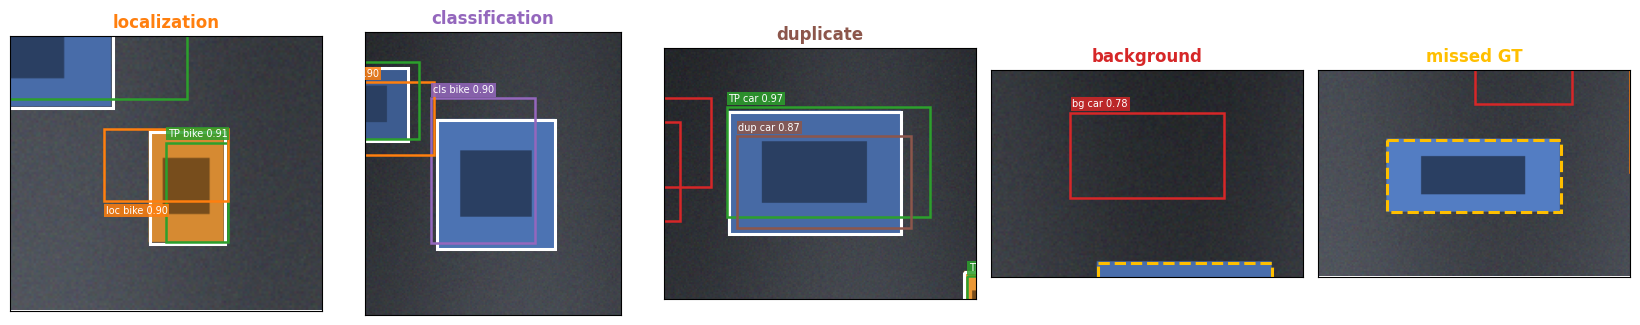

In [17]:
world9, gts9, preds9 = mv.make_case("a bit of everything", seed=7)
res9 = mv.error_breakdown(gts9, preds9)
mv.show_error_gallery(gts9, preds9, res9, world=world9)

### 9.2 The breakdown

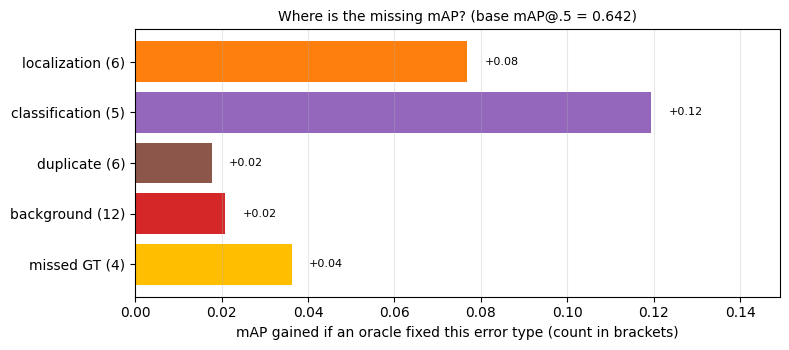

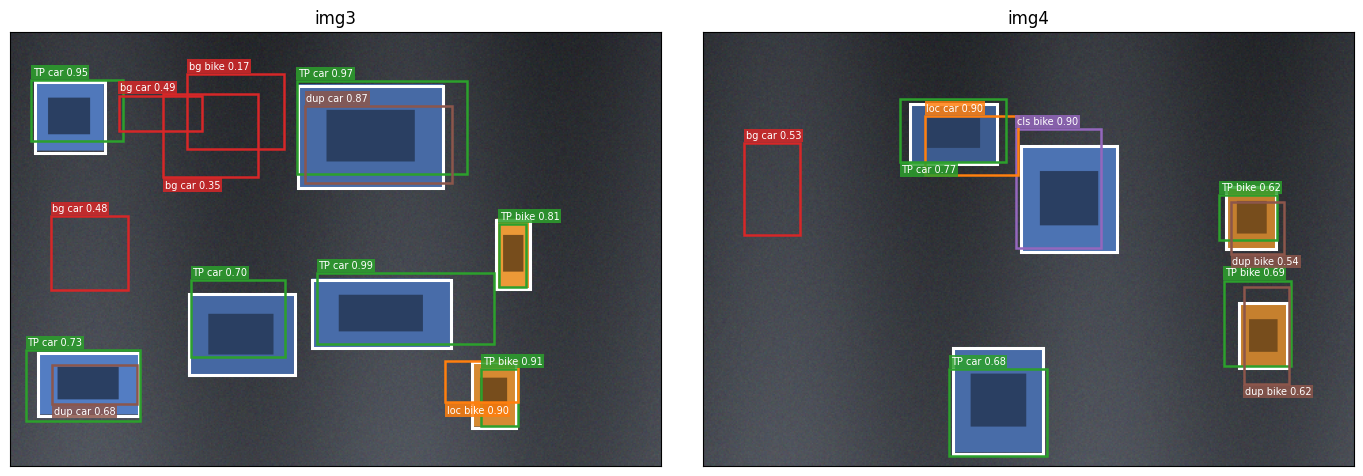

In [18]:
mv.plot_error_breakdown(res9)
mv.show_errors(gts9, preds9, res9, mv.worst_images(gts9, preds9, res9), world=world9)

### 9.3 Count vs. cost

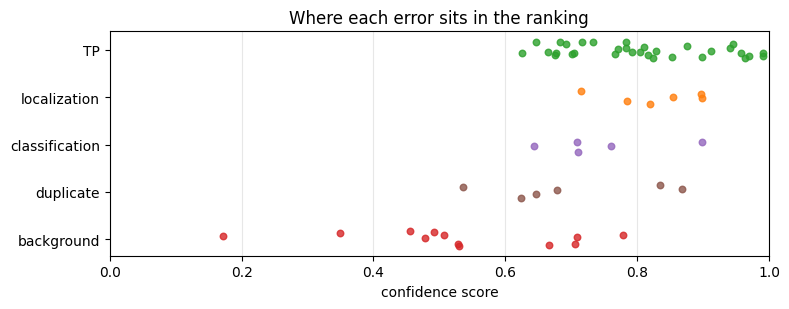

In [ ]:
mv.plot_error   _scores(preds9, res9)